# Relatório de Avaliação — Golden v4 e Comparação com Golden v3

Este notebook consolida a avaliação experimental da ordem de leitura humana anotada sobre as **regiões retificadas no Diamond** (`golden_v4`, 44 páginas concluídas) e compara os resultados com a anotação prévia sobre **blocos do extrator v3** (`golden_v3`, 47 páginas).

Todas as métricas são recalculadas com `src.eval.metrics` a partir das anotações humanas e predições.

In [1]:
import os
import sys
from IPython.display import Markdown, display
from PIL import Image

# Garante raiz do repositório no sys.path
RAIZ = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if RAIZ not in sys.path:
    sys.path.insert(0, RAIZ)

from src.eval.relatorio_v4 import (
    carregar_lote,
    calcular_metricas_base,
    tabela_golden_v4,
    calcular_wilcoxon_holm,
    calcular_efeito_segmentacao,
    calcular_cortes_pagina,
    calcular_vlm_detalhado,
    calcular_layoutlm_dominio,
    carregar_resultados_diamond,
    calcular_custos_humanos,
    carregar_execucoes_llm,
    formatar_markdown,
    plotar_figuras,
    df_resumo_v4,
    df_wilcoxon,
    df_efeito_seg,
    df_cortes,
    df_vlm_comp,
    df_vlm_piores,
    df_dominio,
    df_diamond,
    df_custos,
    df_familiaridade,
    df_execucoes_llm,
)

print('Carregando dados e calculando métricas...')
dados_v4 = carregar_lote('golden_v4')
dados_v3 = carregar_lote('_avaliacao/golden_v3')

regs_v4 = calcular_metricas_base(dados_v4)
regs_v3 = calcular_metricas_base(dados_v3)

resumo_v4, seeds_pont, seeds_suc = tabela_golden_v4(regs_v4, dados_v4)
testes_wilcoxon = calcular_wilcoxon_holm(regs_v4)
comuns_20, efeito_seg = calcular_efeito_segmentacao(regs_v3, regs_v4, dados_v3, dados_v4)
cortes_pag, melhor_llm_v4, melhor_llm_v3 = calcular_cortes_pagina(regs_v4, regs_v3)
comp_vlm, piores5_vlm = calcular_vlm_detalhado(regs_v4, dados_v4, regs_v3)
tab_dominio, pont_res, suc_res = calcular_layoutlm_dominio(regs_v3, regs_v4, efeito_seg)
diam_piloto, diam_treino = carregar_resultados_diamond()
custos_humanos = calcular_custos_humanos(dados_v4, dados_v3)
execucoes_llm = carregar_execucoes_llm()
print('Pronto!')

Carregando dados e calculando métricas...


Pronto!


## 1. Resumo Executivo

In [2]:
md_completo = formatar_markdown(
    resumo_v4, seeds_pont, seeds_suc, testes_wilcoxon, comuns_20,
    efeito_seg, cortes_pag, melhor_llm_v4, melhor_llm_v3,
    comp_vlm, piores5_vlm, tab_dominio, pont_res, suc_res,
    diam_piloto, diam_treino, custos_humanos, execucoes_llm
)
linhas = md_completo.split('\n')
resumo_linhas = []
gravar = False
for l in linhas:
    if l.startswith('## 1. Resumo'):
        gravar = True
        continue
    if gravar and l.startswith('## 2.'):
        break
    if gravar:
        resumo_linhas.append(l)

display(Markdown('\n'.join(resumo_linhas).strip()))

1. O lote `golden_v4` possui **44 páginas concluídas** (1 pulada) anotadas por especialista humano sobre as regiões refinadas manualmente no Diamond.
2. O modelo multimodal **Gemini 3.1 Flash Lite lidera o ranking global**: a configuração **com marcas, sem classes** atingiu **τ = 0,966** (IC 95%: 0,937–0,988; 94,2% de sucessor; 40/44 permutações válidas, 90,9%) e a configuração **com marcas e classes** obteve **τ = 0,962** (IC 95%: 0,925–0,987; 94,4% de sucessor; 38/44 válidas, 86,4%).
3. **Não há efeito mensurável das classes humanas no prompt do VLM**: a diferença de τ entre a versão com classes e sem classes é de apenas **-0,004** (Wilcoxon pareado p = 0,078, sem significância estatística). Além disso, no `golden_v3` (onde o prompt não recebia classes humanas, apenas anotação de tabelas pelo detector), o VLM com marcas já alcançava **τ = 0,924** (88,9% de sucessor). As **marcas visuais sobre a imagem (Set-of-Mark)** têm efeito medido: sem marcas visuais, o τ recua de 0,962 para 0,942 (Wilcoxon pareado p = 0,0087), o acerto de sucessor cai de 94,4% para 90,3% e as permutações válidas caem de 38 para 30 de 44 (86,4% → 68,2%). Mesmo sem marcas, o VLM ainda supera a XY-cut após Holm.
4. As **LLMs de texto** (Qwen 3.8 27B e Gemma 4 31B), avaliadas no Kaggle sobre 2× Tesla T4, recebem exclusivamente texto e coordenadas normalizadas (sem classes e sem imagem). A melhor LLM foi a **LLM Qwen 3.8 27B (few-shot 2)**, com **τ = 0,876**, 75,9% de sucessor correto e 29/44 (65.9%) permutações válidas, ficando abaixo do VLM com marcas (τ = 0,962).
5. Entre os modelos locais e LLMs, embora o **LayoutLM sucessor (semente 42)** (τ = 0,890; média das 3 sementes: τ = 0,870 ± 0,022, sucessor 62,1%) e a melhor LLM de texto (LLM Qwen 3.8 27B (few-shot 2), τ = 0,876) apresentem τ médio numericamente superior à heurística XY-cut (τ = 0,825, sucessor 71,5%), **a diferença não é estatisticamente significativa** após correção de comparações múltiplas por Holm-Bonferroni (p ajustado = 1,00 e 0,92, respectivamente; p bruto = 0,183 e 0,077).
6. Nos testes pareados de Wilcoxon com correção de Holm contra a XY-cut (21 comparações), **apenas as três configurações do VLM obtiveram superioridade estatisticamente significante** (com marcas e classes: p = 5,43e-06; com marcas, sem classes: p = 9,76e-06; sem marcas, com classes: p = 1,98e-04). Nenhuma formulação do LayoutLM, nenhuma das quatro LLMs e nem a ordem ingênua apresentaram diferença significante frente à XY-cut.
7. Nas **20 páginas comuns** entre `golden_v3` e `golden_v4`, o τ do LayoutLM sucessor permaneceu estável (+0,003, p = 0,981), porém a continuidade local sofreu queda de **-10,1 pontos percentuais** no sucessor correto (68,3% → 58,3%, p = 0,055). As LLMs de texto também apresentaram redução de τ nas 20 páginas (Qwen 3.8 27B fs2: 0,932 → 0,845, Δ = -0,087), mas a queda não é estatisticamente significativa (p = 0,121).
8. O custo humano ativo para anotar a ordem sobre as regiões Diamond no `golden_v4` teve mediana de **16,0 s/página** (total de 12,8 min para as 44 páginas). Trata-se de tarefas diferentes da retificação geométrica de caixas e rotulagem de classes no Diamond, com tempo menor (4 a 6 vezes mais rápido que a mediana de 98,5 s no piloto e 67,0 s no treino). Entre as páginas do `golden_v4`, as medianas foram de 17,0 s/página nas 20 páginas já vistas (ordenadas no `golden_v3`) e 15,0 s/página nas 24 novas, sem efeito aparente de familiaridade nesta amostra.

## 2. Resultados no golden_v4 (44 páginas)

In [3]:
df_v4 = df_resumo_v4(resumo_v4)
display(df_v4)

print(f"LayoutLM Pontual (3 sementes): τ médio = {seeds_pont['tau_mean']:.3f} ± {seeds_pont['tau_std']:.3f} | Sucessor = {seeds_pont['suc_mean']:.1%} ± {seeds_pont['suc_std']:.1%}")
print(f"LayoutLM Sucessor (3 sementes): τ médio = {seeds_suc['tau_mean']:.3f} ± {seeds_suc['tau_std']:.3f} | Sucessor = {seeds_suc['suc_mean']:.1%} ± {seeds_suc['suc_std']:.1%}")

,Método,n,τ Kendall,IC 95%,Mediana,p10,Sucessor correto,ARD norm.,Acerto exato,Permutações válidas
0,VLM Gemini 3.1 Flash Lite (sem classes),44,"0,966","0,937–0,988","1,000","0,830","94,2%","0,016","65,9%",40/44 (90.9%)
1,VLM Gemini 3.1 Flash Lite (com marcas),44,"0,962","0,925–0,987","1,000","0,889","94,4%","0,017","68,2%",38/44 (86.4%)
2,VLM Gemini 3.1 Flash Lite (sem marcas),44,"0,942","0,908–0,971","1,000","0,760","90,3%","0,025","52,3%",30/44 (68.2%)
3,LayoutLM sucessor (semente 42),44,"0,890","0,845–0,932","0,940","0,667","66,6%","0,043","9,1%",44/44 (100%)
4,LayoutLM suc. sem viés geom.,44,"0,880","0,820–0,928","0,959","0,771","68,9%","0,049","9,1%",44/44 (100%)
5,LLM Qwen 3.8 27B (few-shot 2),44,"0,876","0,820–0,923","0,958","0,692","75,9%","0,051","36,4%",29/44 (65.9%)
6,LayoutLM sucessor (semente 2),44,"0,873","0,822–0,919","0,951","0,667","65,7%","0,051","6,8%",44/44 (100%)
7,LayoutLM suc. sem texto,44,"0,863","0,796–0,918","0,930","0,670","72,9%","0,055","22,7%",44/44 (100%)
8,LLM Qwen 3.8 27B (zero-shot),44,"0,859","0,781–0,923","0,967","0,569","80,2%","0,058","36,4%",31/44 (70.5%)
9,LayoutLM pontual (semente 1),44,"0,852","0,785–0,905","0,912","0,714","38,2%","0,054","13,6%",44/44 (100%)


LayoutLM Pontual (3 sementes): τ médio = 0.850 ± 0.003 | Sucessor = 37.4% ± 1.9%
LayoutLM Sucessor (3 sementes): τ médio = 0.870 ± 0.022 | Sucessor = 62.1% ± 7.1%


## 3. Testes Pareados contra a XY-cut no golden_v4 (Wilcoxon + Holm)

In [4]:
df_w = df_wilcoxon(testes_wilcoxon)
display(df_w)

,Posto,Método,n,Δ τ médio,p-valor bruto,Limiar Holm,p-valor ajustado,Sobrevive Holm?,Interpretação
0,1,Ordem do detector (entrada embaralhada),44,"-0,772",7.61e-09,2.38e-03,1.60e-07,Sim,Inferior à XY-cut (p < limiar Holm)
1,2,LayoutLM pontual sem layout,44,"-0,700",8.16e-09,2.50e-03,1.63e-07,Sim,Inferior à XY-cut (p < limiar Holm)
2,3,LayoutLM suc. sem layout,44,"-0,545",2.36e-08,2.63e-03,4.49e-07,Sim,Inferior à XY-cut (p < limiar Holm)
3,4,LayoutLM suc. sem posição,44,"-0,504",6.77e-07,2.78e-03,1.22e-05,Sim,Inferior à XY-cut (p < limiar Holm)
4,5,VLM Gemini 3.1 Flash Lite (com marcas),44,"+0,137",5.43e-06,2.94e-03,9.23e-05,Sim,Superior à XY-cut (p < limiar Holm)
5,6,VLM Gemini 3.1 Flash Lite (sem classes),44,"+0,141",9.76e-06,3.13e-03,1.56e-04,Sim,Superior à XY-cut (p < limiar Holm)
6,7,VLM Gemini 3.1 Flash Lite (sem marcas),44,"+0,117",1.98e-04,3.33e-03,2.97e-03,Sim,Superior à XY-cut (p < limiar Holm)
7,8,"Ingênua (topo→base, esq.→dir.)",44,"-0,112",7.39e-03,3.57e-03,1.04e-01,Não,Sem diferença significativa
8,9,Fluxo do PDF (referência silver),44,"-0,193",5.49e-02,3.85e-03,7.13e-01,Não,Sem diferença significativa
9,10,LLM Qwen 3.8 27B (few-shot 2),44,"+0,052",7.68e-02,4.17e-03,9.22e-01,Não,Sem diferença significativa


## 4. Efeito da Segmentação nas 20 Páginas Comuns (golden_v3 × golden_v4)

In [5]:
df_es = df_efeito_seg(efeito_seg)
display(df_es)

,Método,τ v3,τ v4,Δ τ (v4−v3),p (τ),Sucessor v3,Sucessor v4,Δ Sucessor,p (suc.)
0,LayoutLM suc. sem layout,"0,371","0,214","-0,158",5.26e-02,"31,9%","24,3%","-7,6%",2.66e-01
1,LayoutLM suc. sem posição,"0,484","0,205","-0,278",1.13e-02,"71,0%","60,6%","-10,3%",3.86e-02
2,LayoutLM suc. sem texto,"0,880","0,846","-0,034",6.36e-01,"78,5%","64,0%","-14,5%",8.98e-03
3,LayoutLM suc. sem viés geom.,"0,898","0,868","-0,029",7.56e-01,"71,5%","62,5%","-9,0%",6.84e-02
4,Ordem do detector (entrada embaralhada),"0,012","0,030","+0,019",7.47e-01,"7,6%","6,1%","-1,4%",4.92e-01
5,Fluxo do PDF (referência silver),"0,545","0,528","-0,017",6.79e-01,"71,1%","69,5%","-1,5%",5.10e-01
6,LayoutLM pontual (semente 42),"0,867","0,865","-0,002",8.13e-01,"34,8%","32,9%","-2,0%",4.38e-01
7,LayoutLM pontual sem layout,"0,235","0,143","-0,092",6.83e-02,"11,4%","10,1%","-1,4%",3.88e-01
8,LayoutLM sucessor (semente 42),"0,864","0,867","+0,003",9.81e-01,"68,3%","58,3%","-10,1%",5.52e-02
9,LLM Gemma 4 31B (zero-shot),"0,901","0,836","-0,064",7.36e-02,"80,7%","74,6%","-6,1%",4.68e-02


## 5. Avaliação por Tipo de Página no golden_v4

In [6]:
df_c = df_cortes(cortes_pag)
display(df_c)

,Estrutura,n,XY-cut,LayoutLM sucessor (sem. 42),VLM com marcas,Qwen 3.8 27B (few-shot 2)
0,1 coluna (Colunas),24,"0,752","0,920","0,949","0,863"
1,2 colunas (Colunas),13,"0,919","0,847","0,978","0,860"
2,3+ colunas (Colunas),7,"0,901","0,869","0,975","0,951"
3,Sem tabela (Tabela),30,"0,815","0,897","0,948","0,870"
4,Com tabela (Tabela),14,"0,846","0,876","0,992","0,890"


## 6. Avaliação do Modelo Visual-Linguístico (VLM)

In [7]:
print('--- Comparação: Marcas Visuais e Classes Semânticas ---')
display(df_vlm_comp(comp_vlm))

print('\n--- As 5 Piores Páginas do VLM com Marcas ---')
display(df_vlm_piores(piores5_vlm))

--- Comparação: Marcas Visuais e Classes Semânticas ---


,Configuração,n,τ Kendall,Sucessor correto,Permutações válidas,Latência média
0,Com marcas e classes (gemini-3.1-flash-lite),44,"0,962 (0,925–0,987)","94,4%","38/44 (86,4%)","9,4 s/pág."
1,"Com marcas, sem classes (gemini-3.1-flash-lite)",44,"0,966 (0,937–0,988)","94,2%","40/44 (90,9%)","7,4 s/pág."
2,"Sem marcas, com classes (gemini-3.1-flash-lite)",44,"0,942 (0,908–0,971)","90,3%","30/44 (68,2%)","6,2 s/pág."



--- As 5 Piores Páginas do VLM com Marcas ---


,Posto,ID da Página,Blocos,Colunas,Tabelas,Válida?,Rótulos devolvidos,τ Kendall,Sucessor correto
0,1,official_diary_al/DOEAL-2021-10-06-COMPLETO_87...,19,1,0,Sim,19,"0,368","88,9%"
1,2,official_diary_rj/Parte II (Poder Legislativo)...,129,1,0,Não,120,"0,721","57,0%"
2,3,official_diary_mg/executive_official_diary_202...,100,2,0,Não,94,"0,788","32,3%"
3,4,official_diary_se/DOE-SE_2026-01-16_7401.pdf#p31,49,1,0,Sim,49,"0,828","85,4%"
4,5,official_diary_pe/2023-02-02_1-Poder Executivo...,42,3,0,Não,41,"0,889","80,5%"


## 7. LayoutLM Fora do Domínio de Treinamento

In [8]:
df_dom = df_dominio(tab_dominio)
display(df_dom)

,Formulação e Semente,τ no golden_v3 (47 págs.),τ no golden_v4 (44 págs.),Queda relativa τ,Sucessor v3,Sucessor v4,Queda relativa Sucessor
0,LayoutLM Pontual (semente 42),"0,846","0,847","+0,1%","32,8%","35,3%","+7,6%"
1,LayoutLM Pontual (semente 1),"0,879","0,852","-3,1%","42,0%","38,2%","-9,1%"
2,LayoutLM Pontual (semente 2),"0,866","0,850","-1,8%","37,9%","38,8%","+2,5%"
3,LayoutLM Sucessor (semente 42),"0,845","0,890","+5,4%","66,8%","66,6%","-0,2%"
4,LayoutLM Sucessor (semente 1),"0,865","0,847","-2,1%","61,1%","53,8%","-11,8%"
5,LayoutLM Sucessor (semente 2),"0,882","0,873","-0,9%","67,6%","65,7%","-2,8%"


## 8. Avaliação da Segmentação no Diamond

In [9]:
print('--- Diamond Piloto (20 páginas, in-sample) ---')
display(df_diamond(diam_piloto))

print('\n--- Diamond Treino (25 páginas anotadas) ---')
display(df_diamond(diam_treino))

--- Diamond Piloto (20 páginas, in-sample) ---


,Sistema,Páginas,Regiões sistema (gabarito),"F1@0,5","F1@0,9",F1 exata,"F1@0,5 com classe",Classe certa (% palavras)
0,v3,20,523 (754),"0,647","0,512","0,457","0,296","83,8%"
1,proposta,20,764 (754),"0,937","0,870","0,867","0,788","90,7%"
2,regioes_v2,20,763 (754),"0,952","0,893","0,887","0,840","91,4%"
3,regioes,20,764 (754),"0,951","0,891","0,885","0,848","91,5%"
4,rose:rose_piloto_v2,19,667 (674),"0,955","0,908","0,901","0,847","89,3%"
5,regioes_v3+rose:todas,19,686 (674),"0,949","0,887","0,881","0,843","89,3%"
6,regioes_v3+rose:assinatura_cabecalho,19,686 (674),"0,949","0,887","0,881","0,857","91,2%"
7,regioes_v3+rose:assinatura_cabecalho_titulo_ro...,19,686 (674),"0,949","0,887","0,881","0,856","91,1%"



--- Diamond Treino (25 páginas anotadas) ---


,Sistema,Páginas,Regiões sistema (gabarito),"F1@0,5","F1@0,9",F1 exata,"F1@0,5 com classe",Classe certa (% palavras)
0,v3,25,650 (770),"0,689","0,576","0,561","0,324","85,2%"
1,proposta,25,857 (770),"0,916","0,899","0,896","0,789","90,7%"
2,regioes_v2,25,857 (770),"0,916","0,899","0,896","0,789","90,7%"
3,regioes,25,857 (770),"0,916","0,899","0,896","0,793","90,7%"
4,rose:rose_treino,25,838 (770),"0,908","0,883","0,881","0,764","90,0%"
5,regioes_v3+rose:todas,25,857 (770),"0,916","0,899","0,896","0,766","90,0%"
6,regioes_v3+rose:assinatura_cabecalho,25,857 (770),"0,916","0,899","0,896","0,800","91,4%"
7,regioes_v3+rose:assinatura_cabecalho_titulo_ro...,25,857 (770),"0,916","0,899","0,896","0,793","91,1%"


## 9. Custo Humano de Anotação e Custo Computacional

In [10]:
df_cust = df_custos(custos_humanos)
display(df_cust)

print('\n--- Familiaridade no golden_v4 (20 comuns com v3 vs 24 novas) ---')
display(df_familiaridade(custos_humanos))

print('\n--- Custo Computacional das LLMs no Kaggle (2x Tesla T4) ---')
display(df_execucoes_llm(execucoes_llm))

,Conjunto,Tarefa humana,Páginas concluídas,Tempo total ativo,Mediana por página,Média por página,Média por elemento
0,golden_v2,Golden v2 (ordem sobre blocos v3),26,"18,2 min","27,5 s","42,0 s","1,6 s/bloco"
1,golden_v4,Golden v4 (ordem sobre regiões Diamond),44,"12,8 min","16,0 s","17,4 s","0,5 s/bloco"
2,diamond_piloto,Diamond piloto (caixas e classes),20,"55,1 min","98,5 s","165,2 s","4,2 s/bloco"
3,diamond_treino,Diamond treino (caixas e classes),25,"34,6 min","67,0 s","83,1 s","2,6 s/bloco"



--- Familiaridade no golden_v4 (20 comuns com v3 vs 24 novas) ---


,Subconjunto golden_v4,Páginas,Tempo total,Mediana por página,Média por página
0,20 páginas já vistas (ordenadas no v3),20,"6,3 min","17,0 s","19,1 s"
1,24 páginas novas,24,"6,4 min","15,0 s","16,1 s"
2,Total (44 páginas),44,"12,8 min","16,0 s","17,4 s"



--- Custo Computacional das LLMs no Kaggle (2x Tesla T4) ---


,Método,Modelo,Few-shot,GPU,Tempo por página,Permutações válidas,Tempo total
0,LLM Qwen 3.8 27B (zero-shot),qwen3.8:27b,0 ex.,Tesla T4 + Tesla T4,"20,29 s",68.9%,"15,7 min"
1,LLM Qwen 3.8 27B (few-shot 2),qwen3.8:27b,2 ex.,Tesla T4 + Tesla T4,"21,66 s",64.4%,"16,7 min"
2,LLM Gemma 4 31B (zero-shot),gemma4:31b,0 ex.,Tesla T4 + Tesla T4,"27,76 s",82.2%,"21,6 min"
3,LLM Gemma 4 31B (few-shot 2),gemma4:31b,2 ex.,Tesla T4 + Tesla T4,"31,17 s",68.9%,"24,1 min"


## Figuras Comparativas

### Figura 1: Qualidade da Ordem de Leitura no golden_v4 (44 páginas)

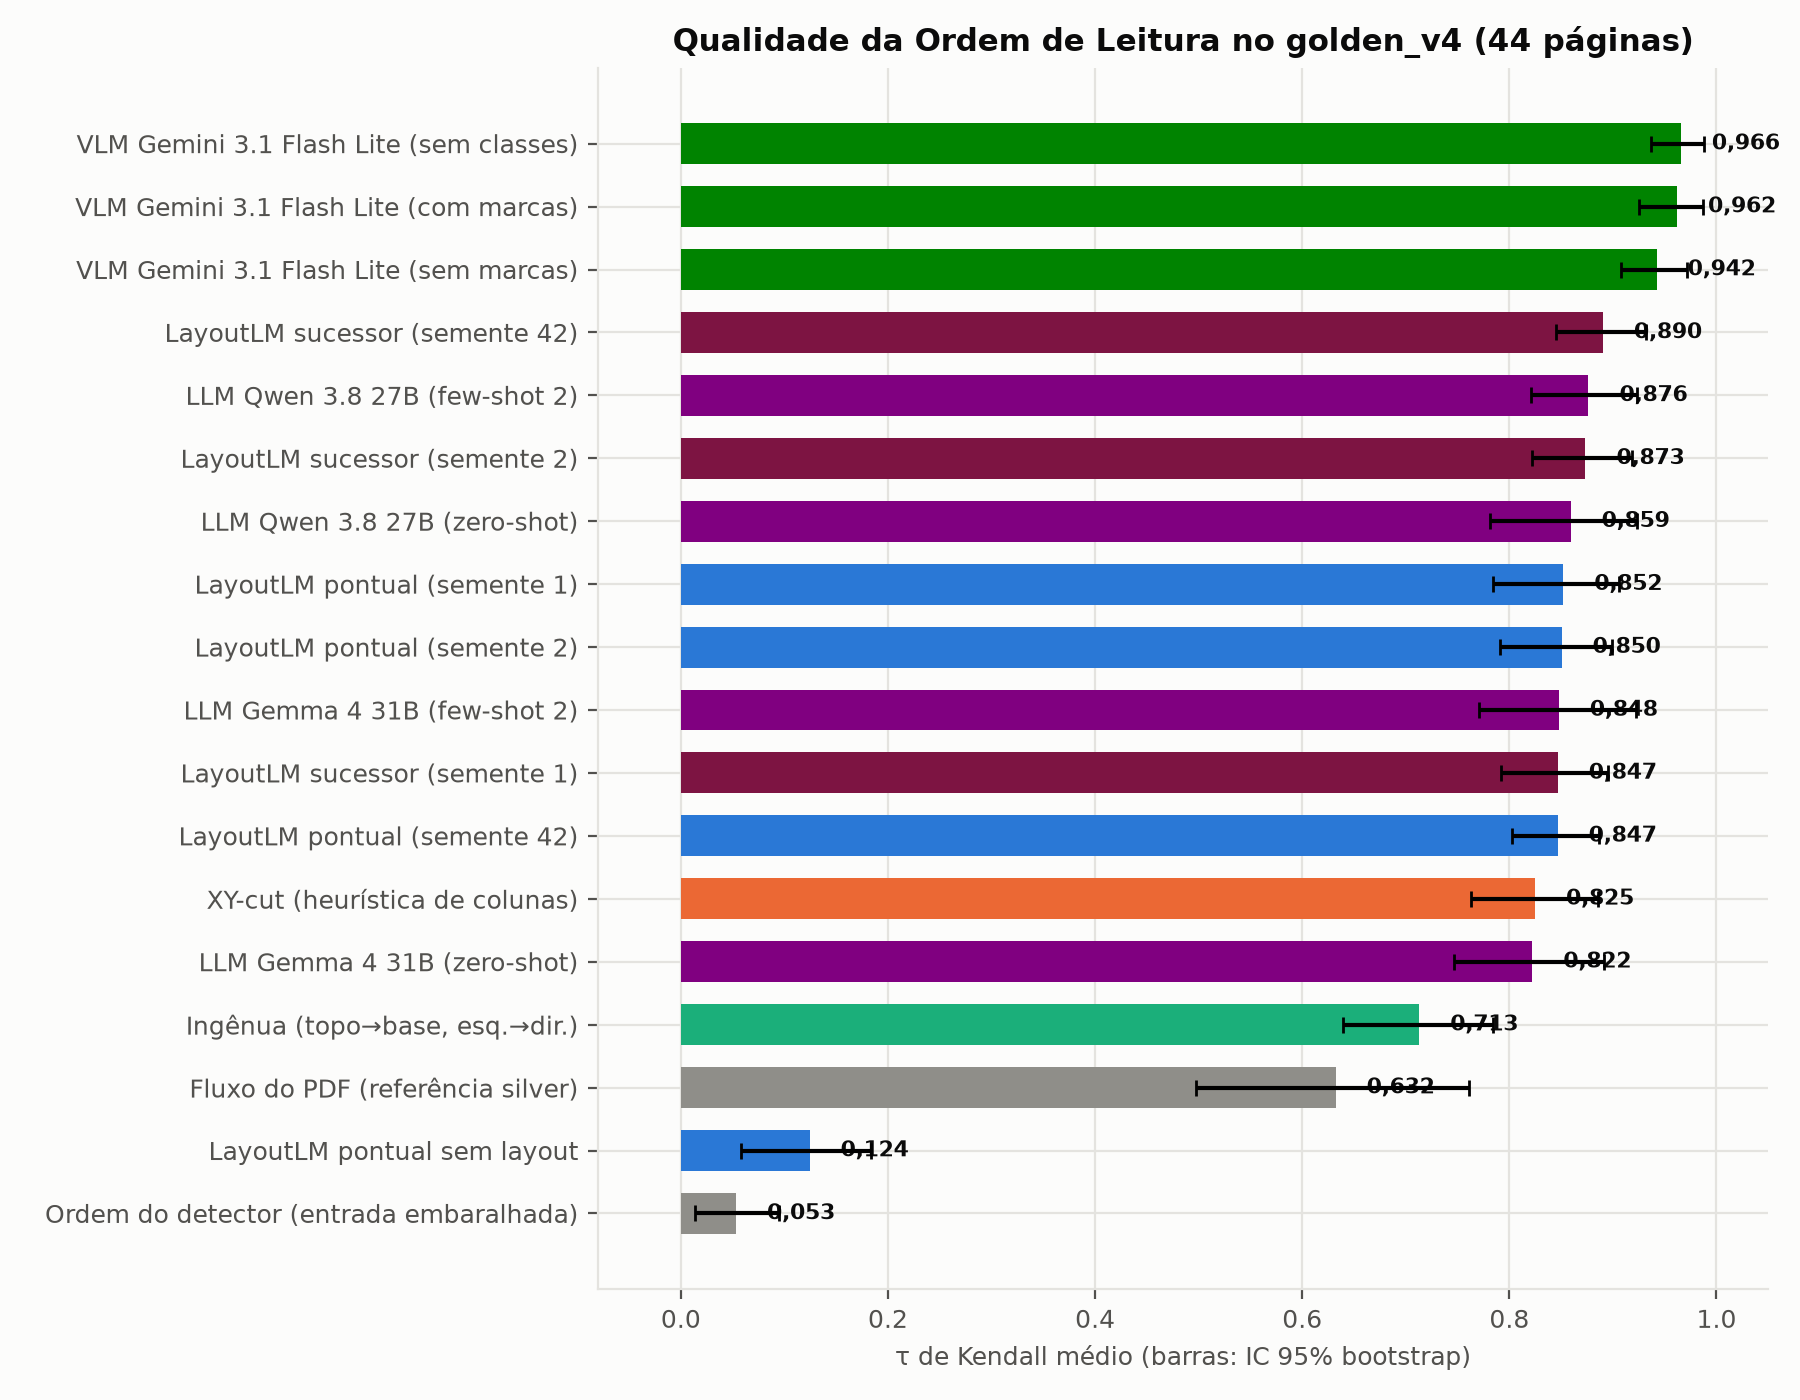

### Figura 2: Efeito da Mudança de Segmentação (20 Páginas Comuns)

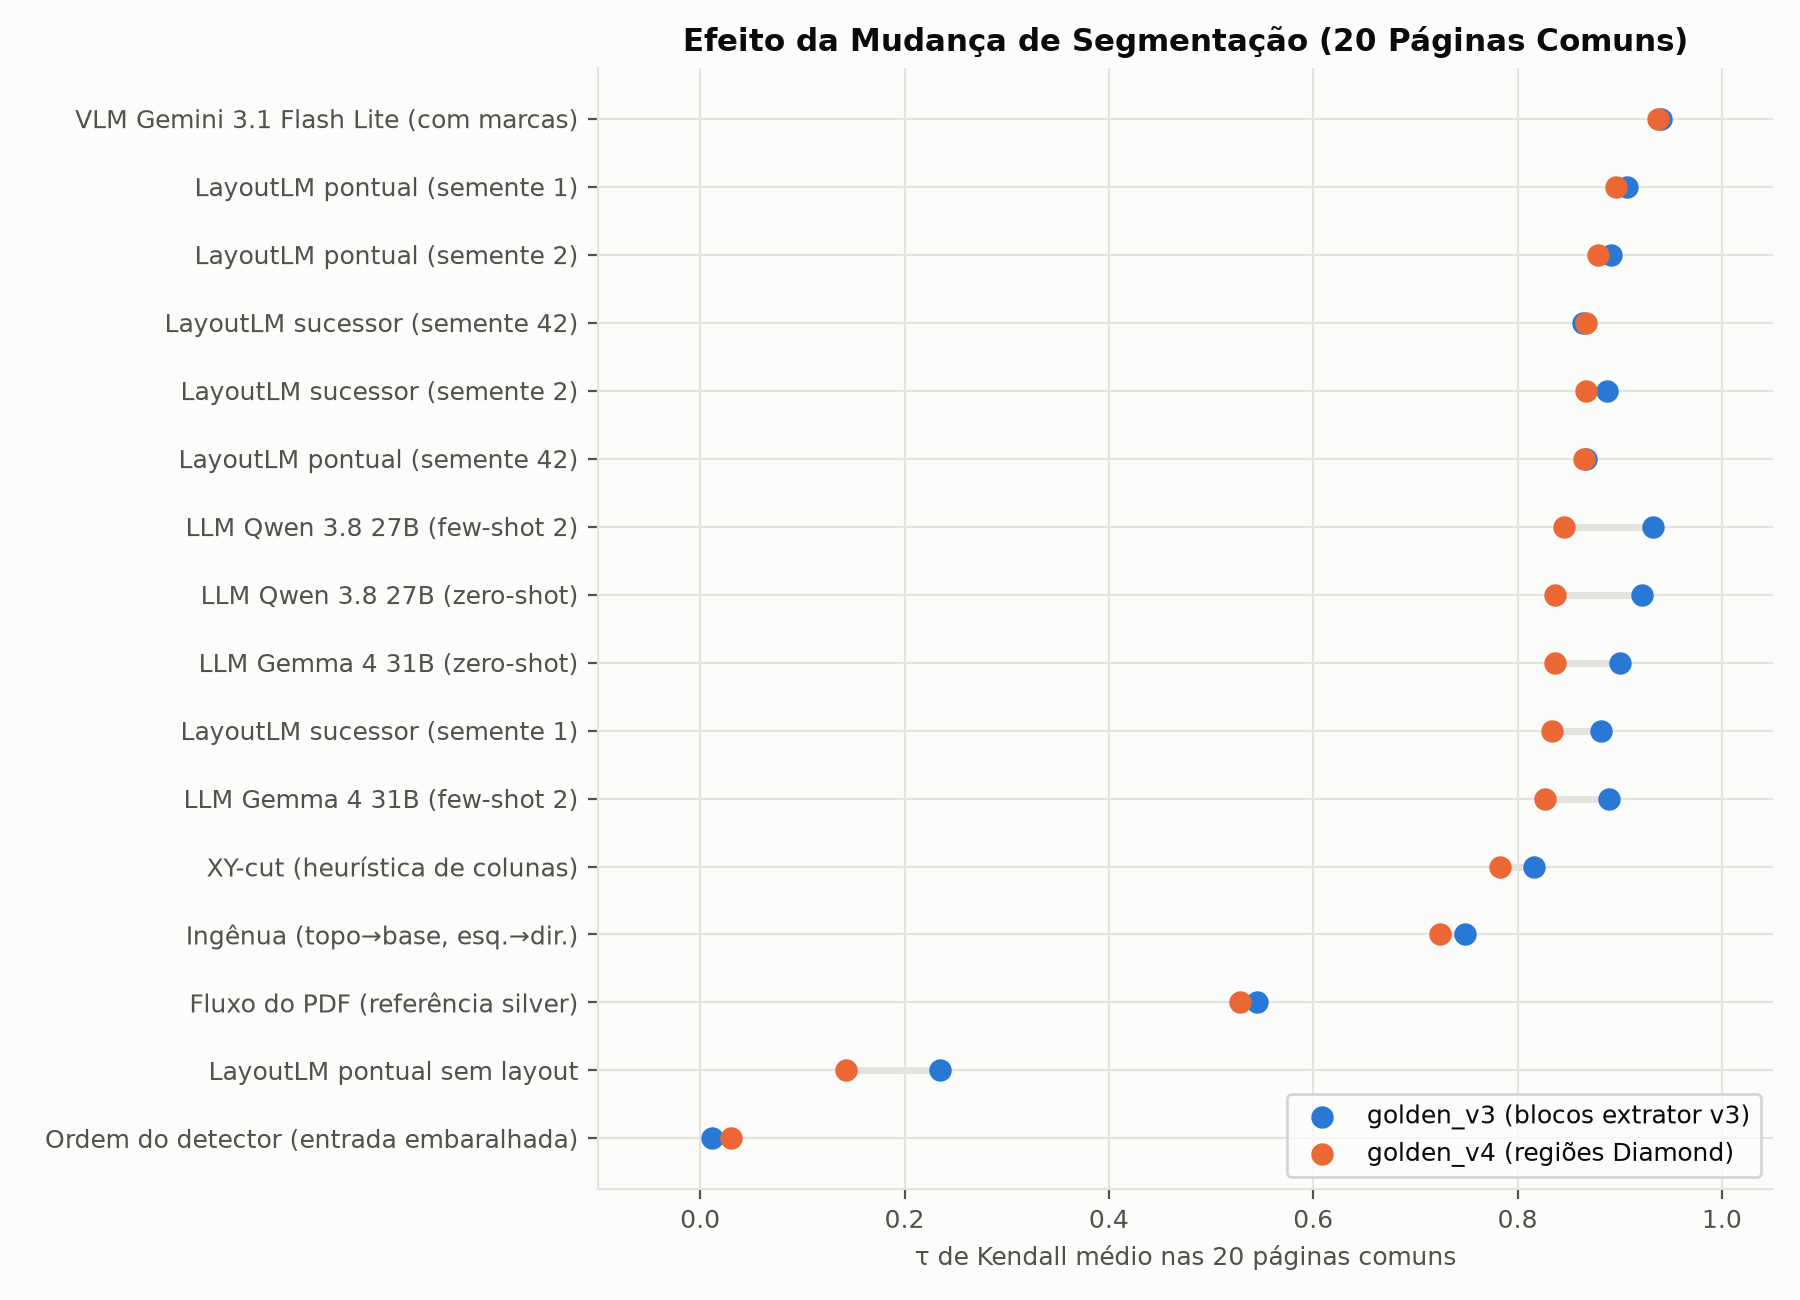

In [11]:
caminho_fig1 = os.path.join(RAIZ, 'docs', 'figuras', 'figura_v4_comparacao_metodos.png')
caminho_fig2 = os.path.join(RAIZ, 'docs', 'figuras', 'figura_v4_efeito_segmentacao.png')

plotar_figuras(resumo_v4, efeito_seg, caminho_fig1, caminho_fig2)

display(Markdown('### Figura 1: Qualidade da Ordem de Leitura no golden_v4 (44 páginas)'))
display(Image.open(caminho_fig1))

display(Markdown('### Figura 2: Efeito da Mudança de Segmentação (20 Páginas Comuns)'))
display(Image.open(caminho_fig2))

## 10. Limitações

1. **Anotador único:** Todas as anotações do golden_v4 e dos lotes do Diamond foram realizadas por um único anotador humano (Pedro alano). Não há medida de concordância inter-anotador para este lote (o teto teórico só foi medido no golden_v1/v2).
2. **Ancoragem da proposta no Diamond:** O anotador corrigiu caixas e classes a partir da pré-anotação gerada pelo algoritmo (proposta), o que ancora as decisões humanas nas fronteiras pré-existentes e infla a aparente precisão da proposta.
3. **Referência reanotada:** Na comparação entre golden_v3 e golden_v4 nas 20 páginas comuns, além da segmentação ter mudado, a ordem de leitura foi refeita, misturando o efeito de corte de blocos com possíveis variações de julgamento do anotador.
4. **Texto só em imagem:** Conforme levantamento de 13/09 registrado no COMUNICACAO_AGENTES.md, **13,8% das páginas do acervo** possuem regiões de texto impressas puramente como imagem (sem palavras digitais na camada do PDF). Como o pipeline atual não inclui OCR, essas regiões permanecem totalmente invisíveis aos modelos de ordenação.
5. **Classes humanas e regras no prompt do VLM:** As classes das caixas fornecidas no prompt do VLM provêm da anotação humana realizada no Diamond, e o prompt incorpora as mesmas regras e convenções do guia seguido pelo anotador. Embora a ablação sem classes demonstre que o modelo mantém τ = 0,966 mesmo sem os rótulos de classe, a presença das diretrizes de ordenação no system prompt do modelo multimodal favorece o VLM em comparação com métodos heurísticos e neurais locais que operam sem acesso a essas regras explícitas.
6. **Segmentação corrigida à mão:** O golden_v4 utiliza segmentação retificada manualmente pelo especialista no Diamond. Dessa forma, os resultados medem o desempenho da ordenação com segmentação ideal, não o pipeline automático completo de ponta a ponta.
7. **VLM em API fechada no nível gratuito:** O modelo Gemini 3.1 Flash Lite foi avaliado via API comercial no nível gratuito. Como a API é fechada, a versão interna do modelo pode mudar pelo provedor, impondo limitações de reprodutibilidade.


## 11. Próximos Passos Sugeridos

1. **Re-treinar o LayoutLM sobre as regiões Diamond:** O modelo atual treinado no extrator v3 preserva o τ global médio (0,850 e 0,870), mas sofreu redução de continuidade local nas 20 páginas comuns (-10,1 pp no sucessor correto para a semente 42, p = 0,055). Hipótese a testar: o re-treino sobre as caixas Diamond restabelece as transições aprendidas entre regiões retificadas.
2. **Avaliar o VLM como fonte de rótulo de ordem:** O Gemini 3.1 Flash Lite com marcas obteve τ = 0,962 (com classes) e τ = 0,966 (sem classes), com 94,4% e 94,2% de sucessor correto (diferença estatisticamente significante frente à XY-cut após correção de Holm, p = 5,43e-06 e p = 9,76e-06). Recomenda-se avaliar formalmente seu emprego para geração de pseudo-rótulos de ordem somente após mensurar a taxa de concordância inter-anotador com humanos em páginas inéditas e estritamente sem classes humanas no prompt (cenário em que atingiu τ = 0,966 no golden_v4 e τ = 0,924 no golden_v3).
3. **Manter as marcas no protocolo do VLM:** A ausência de marcadores visuais (Set-of-Mark) reduziu o desempenho do Gemini 3.1 Flash Lite nas 44 páginas: τ 0,962 → 0,942 (Wilcoxon pareado p = 0,0087), acerto de sucessor de 94,4% para 90,3% e permutações válidas de 38 para 30 de 44 (86,4% → 68,2%). Mesmo sem marcas, o VLM ainda supera a XY-cut após Holm.
4. **Incorporar o Rose no classificador de blocos:** Na avaliação de segmentação em regiões, a comparação entre 
egioes (0,848) e 
egioes_v3+rose:assinatura_cabecalho (0,857) no piloto e 0,793 → 0,800 no treino (25 páginas) resultou em ganho de cerca de 0,01 no F1 com classe, o qual não foi testado estatisticamente.
5. **Escalar a anotação de ordem:** O tempo mediano de ordenação foi de 16,0 s/página no golden_v4 (medianas de 17,0 s nas 20 páginas já vistas e 15,0 s nas 24 novas, sem efeito aparente de familiaridade nesta amostra). Por serem tarefas diferentes, o tempo de ordenação é menor (4 a 6 vezes) que a retificação geométrica de caixas e classes no Diamond (mediana de 67,0 s a 98,5 s), indicando baixo custo temporal para a ordenação sobre regiões pré-corrigidas.
